In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in el_stim_epg_wdark_analysis.py next to this notebook
# (run it as a script to regenerate everything: python el_stim_epg_wdark_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import el_stim_epg_wdark_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

## Optogenetic remapping with a dark period before one of the two cues

The remapping experiment of `R18B05LexA_R60D05Gal4.ipynb`, repeated with a period of darkness before one of the two
cues. Every fly saw both the 0 degree and the 180 degree cue; `post_dark` says which of the two the darkness came
before, so the two conditions are compared within fly rather than between groups.

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
print(f'{sess_manager.sess_df["fly_id"].nunique()} flies, {len(sess_manager.sess_df)} usable sessions')
sess_manager.sess_df.head(20)

10 flies, 50 usable sessions


,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,post_dark,usable,notes,session,fly_id
5,22_04_2026,fly3,baseline-001,1,fictrac-20260422_115036.dat,replication,baseline,0,1,NaN,baseline-001,22_04_2026_fly3_condition_replication
6,22_04_2026,fly3,remap_180deg-003,3,fictrac-20260422_115036.dat,replication,remap_180deg,0,1,NaN,remap_180deg-003,22_04_2026_fly3_condition_replication
7,22_04_2026,fly3,post_180deg-005,5,fictrac-20260422_115036.dat,replication,post_180deg,0,1,NaN,post_180deg-005,22_04_2026_fly3_condition_replication
8,22_04_2026,fly3,remap_0deg_wdark-006,6,fictrac-20260422_115036.dat,replication,remap_0deg,1,1,NaN,remap_0deg_wdark-006,22_04_2026_fly3_condition_replication
9,22_04_2026,fly3,post_0deg_wdark-007,7,fictrac-20260422_115036.dat,replication,post_0deg,1,1,NaN,post_0deg_wdark-007,22_04_2026_fly3_condition_replication
10,23_04_2026,fly1,baseline-000,0,fictrac-20260423_092117.dat,replication,baseline,0,1,NaN,baseline-000,23_04_2026_fly1_condition_replication
11,23_04_2026,fly1,remap_0deg-001,1,fictrac-20260423_092117.dat,replication,remap_0deg,0,1,NaN,remap_0deg-001,23_04_2026_fly1_condition_replication
12,23_04_2026,fly1,post_0deg-002,2,fictrac-20260423_092117.dat,replication,post_0deg,0,1,NaN,post_0deg-002,23_04_2026_fly1_condition_replication
13,23_04_2026,fly1,remap_180deg_wdark-003,3,fictrac-20260423_092117.dat,replication,remap_180deg,1,1,NaN,remap_180deg_wdark-003,23_04_2026_fly1_condition_replication
14,23_04_2026,fly1,post_180deg_wdark-005,5,fictrac-20260423_092117.dat,replication,post_180deg,1,1,NaN,post_180deg_wdark-005,23_04_2026_fly1_condition_replication


## Optogenetic responses

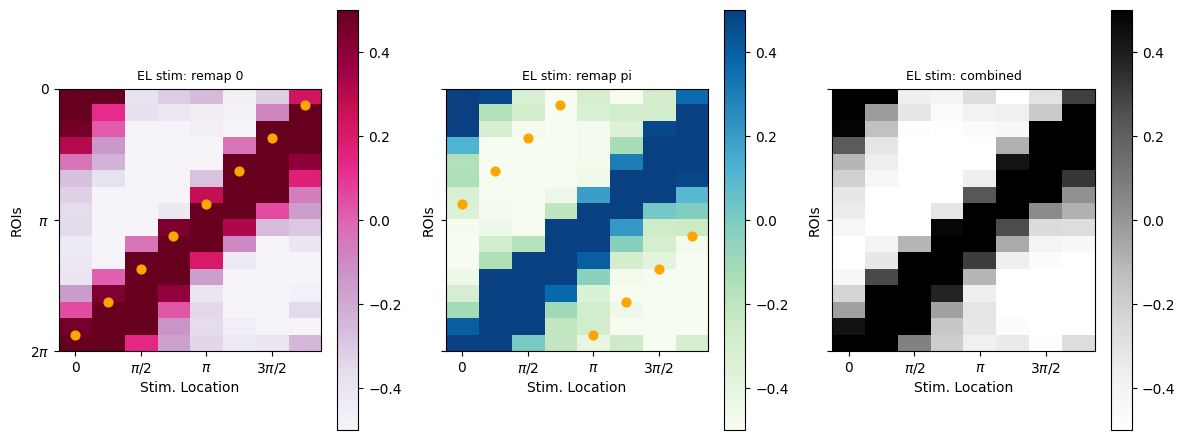

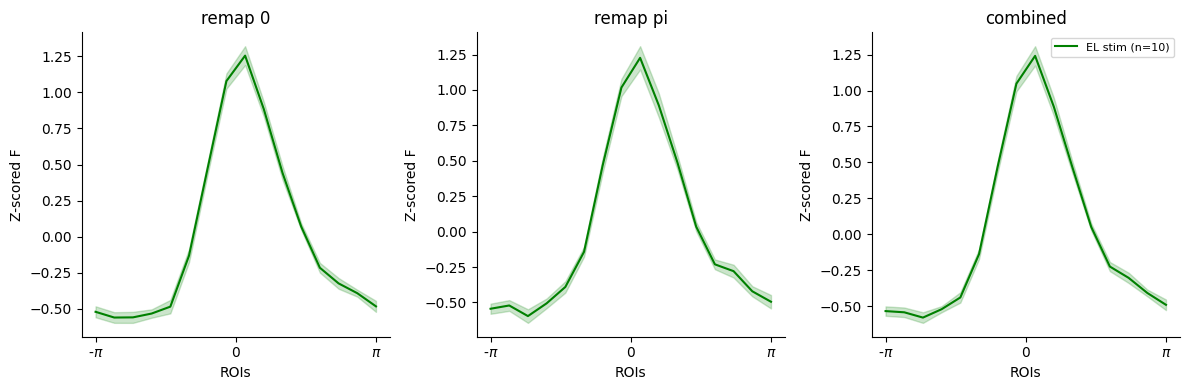

In [3]:
aligned_opto, opto_tables = ana.opto_analysis(sess_manager)
for name, table in opto_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Offset remapping, with and without the dark period

The offset vector length of every scan, the offsets of every fly (split by which cue followed the darkness) and the
remapping error after each of a fly's two cues.

dark before 0 deg remap 0 -0.06854921000385451
dark before 0 deg remap 180 -2.825555617475459
dark before 180 deg remap 0 0.07350342891444812
dark before 180 deg remap 180 2.862719905299364
remapping_error_by_dark_tests


,comparison,n,W,p,p_holm
0,after dark vs no dark,10,16.0,0.275391,0.275391
1,no dark vs chance,10,0.0,0.001953,0.005859
2,after dark vs chance,10,4.0,0.013672,0.027344


n_flies


,group,n_flies
0,dark before 0 deg,5
1,dark before 180 deg,5


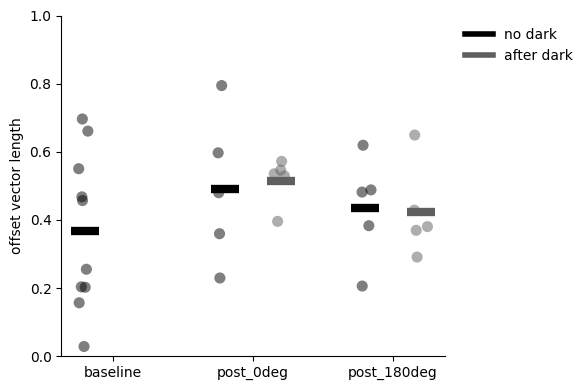

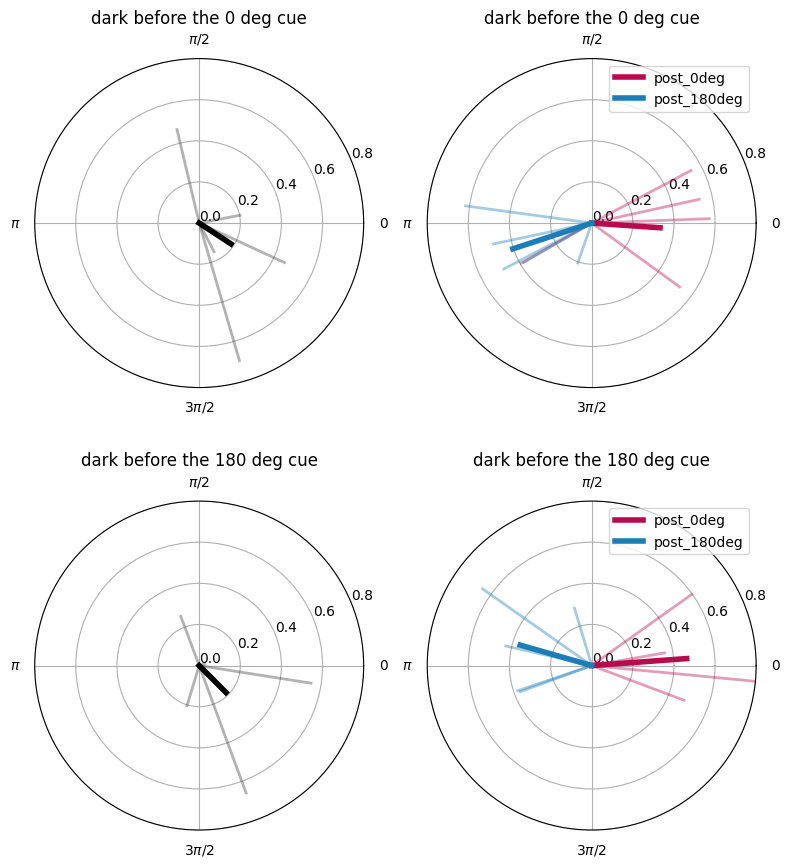

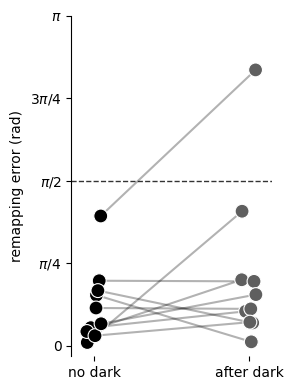

In [7]:
sum_stats, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

In [5]:
sum_stats

,fly_id,baseline mean offset,baseline vec. len,baseline offset var.,baseline post_dark,post_0deg mean offset,post_0deg vec. len,post_0deg offset var.,post_0deg post_dark,post_180deg mean offset,post_180deg vec. len,post_180deg offset var.,post_180deg post_dark,condition
0,22_04_2026_fly3_condition_replication,0.188736,0.202138,0.797862,0.0,0.037380,0.571847,0.428153,1.0,-2.659981,0.481665,0.518335,0.0,dark before 0 deg
1,23_04_2026_fly1_condition_replication,-0.156394,0.550274,0.449726,0.0,0.172352,0.359406,0.640594,0.0,-2.814039,0.380261,0.619739,1.0,dark before 180 deg
2,23_04_2026_fly3_condition_replication,1.928453,0.255064,0.744936,0.0,0.031039,0.229396,0.770604,0.0,1.861943,0.290900,0.709100,1.0,dark before 180 deg
3,27_04_2026_fly1_condition_replication,-1.286001,0.696233,0.303767,0.0,-0.627927,0.528768,0.471232,1.0,3.005892,0.619174,0.380826,0.0,dark before 0 deg
4,27_04_2026_fly2_condition_replication,-1.866419,0.203418,0.796582,0.0,0.618563,0.596839,0.403161,0.0,2.528893,0.649068,0.350932,1.0,dark before 180 deg
5,27_04_2026_fly3_condition_replication,-1.092553,0.156670,0.843330,0.0,-2.624068,0.395629,0.604371,1.0,-1.907068,0.205769,0.794231,0.0,dark before 0 deg
6,28_04_2026_fly1_condition_replication,0.254262,0.028299,0.971701,0.0,-0.359262,0.479711,0.520289,0.0,-2.790675,0.369429,0.630571,1.0,dark before 180 deg
7,04_05_2026_fly1_condition_replication,1.804005,0.467600,0.532400,0.0,0.217479,0.535283,0.464717,1.0,-2.616923,0.382989,0.617011,0.0,dark before 0 deg
8,04_05_2026_fly2_condition_replication,-1.218109,0.660599,0.339401,0.0,-0.095989,0.794342,0.205658,0.0,2.917061,0.428474,0.571526,1.0,dark before 180 deg
9,04_05_2026_fly3_condition_replication,-0.433854,0.456675,0.543325,0.0,0.486803,0.546099,0.453901,1.0,-2.932199,0.488034,0.511966,0.0,dark before 0 deg


## Heatmaps and offset histograms of every fly

In [6]:
plotted_flies = ana.plot_session_figures(sess_manager)
len(plotted_flies)

10